# 05 | Results and Inference

## Joint likelihood-ratio test for Chinese New Year effects

### Purpose

Notebook 04 established the final out-of-sample forecasting results. This notebook addresses a separate explanatory question using the development sample:

> Holding fixed Gregorian month effects and a matched SARIMA error structure constant, do the Chinese New Year pressure and post-CNY normalisation regressors jointly improve the maximised likelihood of the headline month-on-month inflation model?

The comparison uses two genuinely nested models:

- **Restricted model:** an intercept, 11 fixed Gregorian month indicators, and $\mathrm{SARIMA}(1,0,1)(0,0,1)_{12}$ errors;
- **Unrestricted model:** the same specification plus `cny_pressure` and `cny_normalisation`.

The hypotheses are

$$
H_0:
\beta_{P}=\beta_{N}=0,
$$

and

$$
H_1:
\text{at least one of }\beta_{P}\text{ and }\beta_{N}\text{ is nonzero}.
$$

The likelihood-ratio statistic is

$$
LR
=
2\left(\ell_U-\ell_R\right),
$$

where $\ell_R$ and $\ell_U$ are the restricted and unrestricted maximised log likelihoods. Under the conventional regular asymptotic approximation,

$$
LR \overset{a}{\sim} \chi^2_2,
$$

because the null imposes two restrictions.

> **Interpretive boundary:** The test concerns explanatory likelihood within the development sample. It does not test whether the CNY-aware model has lower out-of-sample MAE or RMSE.

## 1. Reproducible setup and project paths

The project loader and CNY-regressor builder are imported from `src/`. The notebook is designed to run from the repository's `notebooks/` directory, and all files are addressed using relative paths. The licensed CEIC extract remains local and outside version control.

In [14]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
from scipy.stats import chi2
from statsmodels.tsa.statespace.sarimax import SARIMAX

PROJECT_ROOT = Path.cwd().parent
if not (PROJECT_ROOT / "src").exists():
    raise RuntimeError("Run this notebook from the repository notebooks/ directory.")
sys.path.insert(0, str(PROJECT_ROOT))

from src.data.load_ceic import load_cpi_series
from src.data.load_cny_calendar import load_cny_calendar
from src.features.cny_regressors import build_cny_regressors

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "china_cpi.csv"
)

CNY_CALENDAR_PATH = (
    PROJECT_ROOT
    / "data"
    / "external"
    / "chinese_new_year_dates.csv"
)

if not DATA_PATH.exists():
    raise FileNotFoundError(
        "The licensed CEIC extract is not available at the documented local path."
    )
if not CNY_CALENDAR_PATH.exists():
    raise FileNotFoundError(
        "The public CNY calendar file is missing from data/external/."
    )


print("Project root: repository root")
print("CPI data path: data/raw/china_cpi.csv")
print(
    "CNY calendar path: "
    "data/external/chinese_new_year_dates.csv"
)

Project root: repository root
CPI data path: data/raw/china_cpi.csv
CNY calendar path: data/external/chinese_new_year_dates.csv


## 2. Lock the sample and matched SARIMA specification

The likelihood-ratio test uses the same January 2006 to December 2014 development sample used for model selection in Notebook 03. Both models use the same trend, fixed month effects, and $\mathrm{SARIMA}(1,0,1)(0,0,1)_{12}$ error specification. The unrestricted model adds exactly two CNY coefficients, so the degrees of freedom are fixed at two.

In [2]:
LR_SAMPLE_START = pd.Timestamp("2006-01-01")
LR_SAMPLE_END = pd.Timestamp("2014-12-01")

LR_ORDER = (1, 0, 1)
LR_SEASONAL_ORDER = (0, 0, 1, 12)
LR_TREND = "c"
LR_RESTRICTIONS = 2
LR_SIGNIFICANCE_LEVEL = 0.05

print(
    "LR-test sample:",
    f"{LR_SAMPLE_START:%Y-%m}",
    "to",
    f"{LR_SAMPLE_END:%Y-%m}",
)
print(
    "Common error specification:",
    f"SARIMA{LR_ORDER}x{LR_SEASONAL_ORDER}",
)
print("Number of restrictions:", LR_RESTRICTIONS)

LR-test sample: 2006-01 to 2014-12
Common error specification: SARIMA(1, 0, 1)x(0, 0, 1, 12)
Number of restrictions: 2


## 3. Load headline month-on-month inflation

The test is fitted to 108 complete monthly observations. The target is the published headline month-on-month inflation rate, expressed in percentage points. The assertions verify the exact sample endpoints, monthly frequency, and absence of missing values.

In [3]:
cpi = load_cpi_series(DATA_PATH).asfreq("MS")

headline_lr = (
    cpi.loc[
        LR_SAMPLE_START:LR_SAMPLE_END,
        "headline_mom_published",
    ]
    .astype(float)
    .asfreq("MS")
)

assert headline_lr.index.min() == LR_SAMPLE_START
assert headline_lr.index.max() == LR_SAMPLE_END
assert headline_lr.notna().all()
assert headline_lr.index.freqstr == "MS"
assert len(headline_lr) == 108

print("Observations:", len(headline_lr))
print("Frequency:", headline_lr.index.freqstr)

display(headline_lr.describe().to_frame("headline_mom_published"))

Observations: 108
Frequency: MS


,headline_mom_published
count,108.000000
mean,0.251852
std,0.581085
min,-0.900000
25%,-0.100000
50%,0.200000
75%,0.525000
max,2.600000


## 4. Reconstruct the locked CNY regressors

The moving-holiday definitions are carried forward unchanged from Notebook 03. The displayed rows show only months receiving a positive allocation from either CNY phase. The allocations move across January, February, and occasionally March as the lunar holiday shifts relative to the Gregorian calendar.

In [4]:
cny_calendar_lr = load_cny_calendar(
    CNY_CALENDAR_PATH,
    start_year=LR_SAMPLE_START.year,
    end_year=LR_SAMPLE_END.year,
)

cny_result_lr = build_cny_regressors(
    cny_calendar=cny_calendar_lr,
    start_date=LR_SAMPLE_START,
    end_date=LR_SAMPLE_END,
)

cny_regressors_lr = (
    cny_result_lr.monthly
    .reindex(headline_lr.index)
    .asfreq("MS")
)

assert cny_regressors_lr.index.equals(headline_lr.index)
assert cny_regressors_lr.notna().all().all()

cny_affected_months_lr = cny_regressors_lr.loc[
    cny_regressors_lr.sum(axis=1) > 0
]

display(cny_affected_months_lr)

,cny_pressure,cny_normalisation
date,,
2006-01-01,0.586207,0.000000
2006-02-01,0.413793,1.000000
2007-02-01,0.862069,0.000000
2007-03-01,0.137931,1.000000
2008-01-01,0.275862,0.000000
2008-02-01,0.724138,0.571429
2008-03-01,0.000000,0.428571
2009-01-01,0.689655,0.000000
2009-02-01,0.310345,1.000000


### Locked moving-holiday definitions

- `cny_pressure` allocates the 29-day period from 14 days before through 14 days after Chinese New Year across the affected Gregorian months.
- `cny_normalisation` allocates the 14-day period from 15 through 28 days after Chinese New Year across the affected Gregorian months.

For each CNY year and phase, the monthly fractions sum to one. These definitions were selected during development and are not redesigned after observing the inferential result.

## 5. Construct matched design matrices

The restricted and unrestricted models must be identical except for the two tested regressors. Both therefore contain:

- an intercept through `trend="c"`;
- 11 month indicators, with January omitted as the reference month;
- the same SARIMA error specification.

The unrestricted design adds only `cny_pressure` and `cny_normalisation`. In parameter notation,

$$
y_t
=
\alpha
+
\sum_{m=2}^{12}\gamma_m M_{m,t}
+
\beta_P H^P_t
+
\beta_N H^N_t
+
\nu_t,
$$

where $\nu_t$ follows the matched $\mathrm{SARIMA}(1,0,1)(0,0,1)_{12}$ error process. Under the restricted model, $\beta_P=\beta_N=0$.

In [5]:
month_indicators_lr = pd.get_dummies(
    headline_lr.index.month,
    prefix="month",
    drop_first=True,
    dtype=float,
)
month_indicators_lr.index = headline_lr.index

restricted_exog_lr = month_indicators_lr.copy().asfreq("MS")

unrestricted_exog_lr = pd.concat(
    [
        month_indicators_lr,
        cny_regressors_lr[
            [
                "cny_pressure",
                "cny_normalisation",
            ]
        ],
    ],
    axis=1,
).asfreq("MS")

assert restricted_exog_lr.index.equals(headline_lr.index)
assert unrestricted_exog_lr.index.equals(headline_lr.index)
assert restricted_exog_lr.notna().all().all()
assert unrestricted_exog_lr.notna().all().all()
assert (
    unrestricted_exog_lr.shape[1]
    - restricted_exog_lr.shape[1]
    == LR_RESTRICTIONS
)

print("Restricted regressors:", restricted_exog_lr.shape[1])
print("Unrestricted regressors:", unrestricted_exog_lr.shape[1])
print(
    "Additional CNY regressors:",
    unrestricted_exog_lr.shape[1]
    - restricted_exog_lr.shape[1],
)

print("\nRestricted columns:")
print(restricted_exog_lr.columns.tolist())
print("\nUnrestricted columns:")
print(unrestricted_exog_lr.columns.tolist())

Restricted regressors: 11
Unrestricted regressors: 13
Additional CNY regressors: 2

Restricted columns:
['month_2', 'month_3', 'month_4', 'month_5', 'month_6', 'month_7', 'month_8', 'month_9', 'month_10', 'month_11', 'month_12']

Unrestricted columns:
['month_2', 'month_3', 'month_4', 'month_5', 'month_6', 'month_7', 'month_8', 'month_9', 'month_10', 'month_11', 'month_12', 'cny_pressure', 'cny_normalisation']


## 6. Fit the restricted model by maximum likelihood

The restricted model estimates the fixed Gregorian month effects and SARIMA nuisance parameters while imposing both CNY coefficients equal to zero. Its maximised log likelihood is the benchmark likelihood under the null hypothesis.

In [6]:
restricted_lr_model = SARIMAX(
    endog=headline_lr,
    exog=restricted_exog_lr,
    order=LR_ORDER,
    seasonal_order=LR_SEASONAL_ORDER,
    trend=LR_TREND,
    enforce_stationarity=True,
    enforce_invertibility=True,
)

restricted_lr_fit = restricted_lr_model.fit(
    disp=False,
    maxiter=500,
)

restricted_converged = bool(
    restricted_lr_fit.mle_retvals.get("converged", False)
)

print("Restricted model converged:", restricted_converged)
print("Restricted log likelihood:", restricted_lr_fit.llf)
print("Restricted parameter count:", len(restricted_lr_fit.params))

Restricted model converged: True
Restricted log likelihood: -30.59487313818755
Restricted parameter count: 16


## 7. Fit the unrestricted model by maximum likelihood

The unrestricted model estimates the same nuisance parameters and additionally estimates the two CNY coefficients. Because the restricted model is nested within it, the unrestricted maximised likelihood should not be lower, apart from negligible numerical tolerance.

In [7]:
unrestricted_lr_model = SARIMAX(
    endog=headline_lr,
    exog=unrestricted_exog_lr,
    order=LR_ORDER,
    seasonal_order=LR_SEASONAL_ORDER,
    trend=LR_TREND,
    enforce_stationarity=True,
    enforce_invertibility=True,
)

unrestricted_lr_fit = unrestricted_lr_model.fit(
    disp=False,
    maxiter=500,
)

unrestricted_converged = bool(
    unrestricted_lr_fit.mle_retvals.get("converged", False)
)

print("Unrestricted model converged:", unrestricted_converged)
print("Unrestricted log likelihood:", unrestricted_lr_fit.llf)
print("Unrestricted parameter count:", len(unrestricted_lr_fit.params))

Unrestricted model converged: True
Unrestricted log likelihood: -16.10223360183099
Unrestricted parameter count: 18


## 8. Verify that the LR comparison is valid

Before calculating the statistic, the notebook verifies convergence, finite parameter estimates, equal observations, identical ordinary and seasonal orders, exactly two additional parameters, and a non-decreasing unrestricted likelihood. These checks ensure that the LR statistic isolates the joint contribution of the two CNY regressors rather than a change in sample or SARIMA architecture.

In [8]:
assert restricted_converged, (
    "The restricted model did not converge."
)
assert unrestricted_converged, (
    "The unrestricted model did not converge."
)
assert np.isfinite(restricted_lr_fit.params).all()
assert np.isfinite(unrestricted_lr_fit.params).all()
assert restricted_lr_fit.nobs == unrestricted_lr_fit.nobs
assert restricted_lr_fit.model.endog.shape == (
    unrestricted_lr_fit.model.endog.shape
)
assert restricted_lr_fit.model.order == unrestricted_lr_fit.model.order
assert restricted_lr_fit.model.seasonal_order == (
    unrestricted_lr_fit.model.seasonal_order
)
assert (
    len(unrestricted_lr_fit.params)
    - len(restricted_lr_fit.params)
    == LR_RESTRICTIONS
)
assert unrestricted_lr_fit.llf >= restricted_lr_fit.llf - 1e-8, (
    "The unrestricted likelihood is unexpectedly below "
    "the restricted likelihood."
)

print("Matched-model LR comparison verified.")

Matched-model LR comparison verified.


## 9. Calculate the likelihood-ratio test

The observed log likelihoods are

$$
\ell_R=-30.595,
\qquad
\ell_U=-16.102.
$$

Therefore,

$$
LR
=
2\left[-16.102-(-30.595)\right]
=
28.985.
$$

The p-value is calculated from the upper tail of the conventional $\chi^2_2$ reference distribution using `chi2.sf`, which is numerically preferable to subtracting a cumulative probability from one.

In [9]:
restricted_log_likelihood = float(restricted_lr_fit.llf)
unrestricted_log_likelihood = float(unrestricted_lr_fit.llf)

lr_statistic = 2 * (
    unrestricted_log_likelihood
    - restricted_log_likelihood
)
lr_degrees_of_freedom = LR_RESTRICTIONS
lr_p_value = chi2.sf(
    lr_statistic,
    df=lr_degrees_of_freedom,
)

lr_test_result = pd.DataFrame(
    {
        "restricted_log_likelihood": [
            restricted_log_likelihood
        ],
        "unrestricted_log_likelihood": [
            unrestricted_log_likelihood
        ],
        "lr_statistic": [lr_statistic],
        "degrees_of_freedom": [
            lr_degrees_of_freedom
        ],
        "p_value": [lr_p_value],
    }
)

display(lr_test_result)

,restricted_log_likelihood,unrestricted_log_likelihood,lr_statistic,degrees_of_freedom,p_value
0,-30.594873,-16.102234,28.985279,2,5.080736e-07


## 10. Compare the fitted models descriptively

The unrestricted model uses two additional parameters but still has substantially lower AIC and BIC. These information criteria support the CNY-augmented model after penalising its additional complexity, but they are supporting descriptive evidence rather than substitutes for the joint LR test.

In [10]:
lr_model_comparison = pd.DataFrame(
    {
        "model": [
            "Restricted",
            "Unrestricted",
        ],
        "month_indicators": [
            "Yes",
            "Yes",
        ],
        "cny_pressure": [
            "No",
            "Yes",
        ],
        "cny_normalisation": [
            "No",
            "Yes",
        ],
        "parameters": [
            len(restricted_lr_fit.params),
            len(unrestricted_lr_fit.params),
        ],
        "log_likelihood": [
            restricted_lr_fit.llf,
            unrestricted_lr_fit.llf,
        ],
        "aic": [
            restricted_lr_fit.aic,
            unrestricted_lr_fit.aic,
        ],
        "bic": [
            restricted_lr_fit.bic,
            unrestricted_lr_fit.bic,
        ],
        "converged": [
            restricted_converged,
            unrestricted_converged,
        ],
    }
)

display(lr_model_comparison)

,model,month_indicators,cny_pressure,cny_normalisation,parameters,log_likelihood,aic,bic,converged
0,Restricted,Yes,No,No,16,-30.594873,93.189746,136.103846,True
1,Unrestricted,Yes,Yes,Yes,18,-16.102234,68.204467,116.482829,True


## 11. Interpret the CNY coefficients

The unrestricted estimates have the expected signs:

- the pressure coefficient is positive, $\widehat{\beta}_P=1.211$;
- the post-CNY normalisation coefficient is negative, $\widehat{\beta}_N=-0.611$.

Because each regressor is a fractional monthly allocation, a coefficient represents the estimated contribution when the entire corresponding phase falls within one month. For example, if 60% of the pressure phase falls within a month, the fitted contribution is $0.60\widehat{\beta}_P$.

Both individual 95% confidence intervals exclude zero. These individual results are useful supporting evidence, but the project's principal inferential conclusion is the joint LR test of both coefficients.

In [11]:
cny_parameter_names = [
    "cny_pressure",
    "cny_normalisation",
]

unrestricted_confidence_intervals = (
    unrestricted_lr_fit.conf_int()
)

cny_coefficient_results = pd.DataFrame(
    {
        "estimate": unrestricted_lr_fit.params.loc[
            cny_parameter_names
        ],
        "standard_error": unrestricted_lr_fit.bse.loc[
            cny_parameter_names
        ],
        "z_statistic": unrestricted_lr_fit.tvalues.loc[
            cny_parameter_names
        ],
        "individual_p_value": (
            unrestricted_lr_fit.pvalues.loc[
                cny_parameter_names
            ]
        ),
        "ci_lower": (
            unrestricted_confidence_intervals.loc[
                cny_parameter_names
            ].iloc[:, 0]
        ),
        "ci_upper": (
            unrestricted_confidence_intervals.loc[
                cny_parameter_names
            ].iloc[:, 1]
        ),
    }
)

display(cny_coefficient_results)

,estimate,standard_error,z_statistic,individual_p_value,ci_lower,ci_upper
cny_pressure,1.210581,0.476523,2.540444,0.011071,0.276612,2.144549
cny_normalisation,-0.610532,0.218827,-2.790017,0.005271,-1.039426,-0.181638


## 12. Formal decision

At the 5% significance level, the result is

$$
LR=28.985,
\qquad
\mathrm{df}=2,
\qquad
p=5.081\times10^{-7}.
$$

The null hypothesis $H_0:\beta_P=\beta_N=0$ is rejected. The development sample provides strong evidence that the CNY pressure and post-CNY normalisation regressors jointly improve the maximised likelihood, conditional on fixed Gregorian month effects and the matched SARIMA error structure.

In [12]:
if lr_p_value < LR_SIGNIFICANCE_LEVEL:
    lr_decision = "Reject H0"
    lr_interpretation = (
        "The development-sample likelihood-ratio test provides "
        "strong evidence that the CNY pressure and post-CNY "
        "normalisation regressors jointly improve the maximised "
        "likelihood of the headline month-on-month inflation "
        "model, conditional on fixed Gregorian month effects and "
        "the matched SARIMA error specification."
    )
else:
    lr_decision = "Fail to reject H0"
    lr_interpretation = (
        "The development-sample likelihood-ratio test does not "
        "provide sufficient evidence that the CNY pressure and "
        "post-CNY normalisation regressors jointly improve the "
        "maximised likelihood of the headline month-on-month "
        "inflation model, conditional on fixed Gregorian month "
        "effects and the matched SARIMA error specification."
    )

print(f"LR statistic: {lr_statistic:.4f}")
print("Degrees of freedom:", lr_degrees_of_freedom)
print(f"P-value: {lr_p_value:.3e}")
print("Decision:", lr_decision)
print("Interpretation:", lr_interpretation)

LR statistic: 28.9853
Degrees of freedom: 2
P-value: 5.081e-07
Decision: Reject H0
Interpretation: The development-sample likelihood-ratio test provides strong evidence that the CNY pressure and post-CNY normalisation regressors jointly improve the maximised likelihood of the headline month-on-month inflation model, conditional on fixed Gregorian month effects and the matched SARIMA error specification.


## 13. Interpretation and limitations

### Explanatory fit versus forecast performance

The LR test and the final forecast evaluation answer different questions:

- the **LR test** asks whether the CNY variables improve the model's in-sample maximised likelihood;
- the **forecast comparison** asks whether CNY-aware forecasts have lower out-of-sample loss.

The project finds strong explanatory evidence for the CNY variables but no uniform medium- or long-horizon forecasting advantage. This is not contradictory. A variable may explain recurring monthly movements while the broader recursively projected inflation path remains inaccurate.

### Near-invertibility caveat

The matched SARIMA error model contains a seasonal MA nuisance parameter estimated close to the invertibility boundary. The conventional chi-square calibration relies on the likelihood being well approximated locally by a smooth quadratic surface. Near a boundary, the likelihood may be flatter or more asymmetric in the nuisance-parameter direction, so the finite-sample distribution of the LR statistic may differ from the ideal $\chi^2_2$ approximation.

This caveat affects confidence in the precise calibration of the p-value, not the arithmetic of

$$
LR=2(\ell_U-\ell_R).
$$

The observed statistic is far above the conventional 5% critical value, both CNY coefficients have the expected signs with intervals excluding zero, and AIC and BIC also prefer the unrestricted model. The qualitative conclusion is therefore compelling, although the asymptotic limitation should be acknowledged.

### Conclusion

The matched restricted and unrestricted models used the same 108 monthly observations, intercept treatment, fixed Gregorian month effects, and $\mathrm{SARIMA}(1,0,1)(0,0,1)_{12}$ error specification. Adding the CNY pressure and post-CNY normalisation regressors increased the maximised log likelihood from $-30.595$ to $-16.102$, producing $LR=28.985$ with two degrees of freedom and $p=5.081\times10^{-7}$. The null hypothesis that both CNY coefficients are zero is rejected. The positive pressure estimate and negative normalisation estimate provide economically coherent evidence that the moving holiday adds explanatory information. This likelihood result remains distinct from the out-of-sample finding that the CNY-aware models do not uniformly improve multi-step MAE or RMSE.

## 14. Save reproducibility and publication-ready outputs

The notebook preserves complete derived inference tables under `data/processed/` and exports a curated public result set under `outputs/`:

- the joint likelihood-ratio test;
- the matched restricted-versus-unrestricted model comparison;
- the two CNY coefficient estimates and confidence intervals;
- a coefficient plot suitable for the README or presentation.

These are compact derived results and do not reproduce the licensed CEIC observation history.

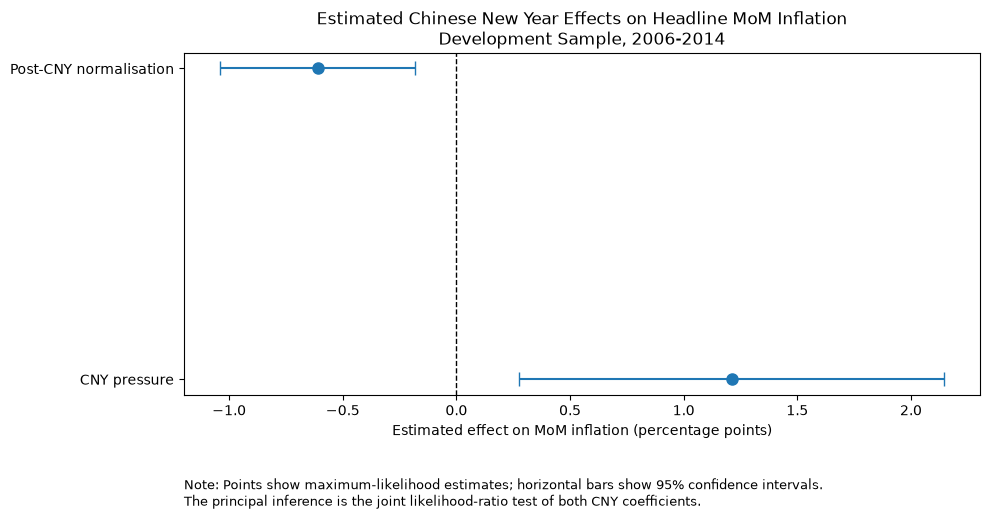

Saved: data/processed/headline_cny_likelihood_ratio_test.csv
Saved: data/processed/headline_cny_lr_model_comparison.csv
Saved: data/processed/headline_cny_coefficient_results.csv
Saved: outputs/tables/05_cny_likelihood_ratio_test.csv
Saved: outputs/tables/05_cny_lr_model_comparison.csv
Saved: outputs/tables/05_cny_coefficient_results.csv
Saved: outputs/figures/05_cny_coefficient_estimates.png


In [13]:
# Export final inference results

from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd


PROCESSED_OUTPUT_PATH = PROJECT_ROOT / "data" / "processed"
PUBLIC_TABLE_PATH = PROJECT_ROOT / "outputs" / "tables"
PUBLIC_FIGURE_PATH = PROJECT_ROOT / "outputs" / "figures"

PROCESSED_OUTPUT_PATH.mkdir(
    parents=True,
    exist_ok=True,
)
PUBLIC_TABLE_PATH.mkdir(
    parents=True,
    exist_ok=True,
)
PUBLIC_FIGURE_PATH.mkdir(
    parents=True,
    exist_ok=True,
)


# 1. Save complete derived results for reproducibility

lr_processed_path = (
    PROCESSED_OUTPUT_PATH
    / "headline_cny_likelihood_ratio_test.csv"
)

model_comparison_processed_path = (
    PROCESSED_OUTPUT_PATH
    / "headline_cny_lr_model_comparison.csv"
)

coefficient_processed_path = (
    PROCESSED_OUTPUT_PATH
    / "headline_cny_coefficient_results.csv"
)

lr_test_result.to_csv(
    lr_processed_path,
    index=False,
)

lr_model_comparison.to_csv(
    model_comparison_processed_path,
    index=False,
)

cny_coefficient_results.to_csv(
    coefficient_processed_path,
    index_label="regressor",
)


# 2. Save curated publication-ready tables

lr_public_path = (
    PUBLIC_TABLE_PATH
    / "05_cny_likelihood_ratio_test.csv"
)

model_comparison_public_path = (
    PUBLIC_TABLE_PATH
    / "05_cny_lr_model_comparison.csv"
)

coefficient_public_path = (
    PUBLIC_TABLE_PATH
    / "05_cny_coefficient_results.csv"
)

lr_test_result.to_csv(
    lr_public_path,
    index=False,
    float_format="%.6f",
)

lr_model_comparison.to_csv(
    model_comparison_public_path,
    index=False,
    float_format="%.6f",
)

cny_coefficient_results.to_csv(
    coefficient_public_path,
    index_label="regressor",
    float_format="%.6f",
)


# 3. Validate the inference objects before plotting

required_lr_columns = {
    "restricted_log_likelihood",
    "unrestricted_log_likelihood",
    "lr_statistic",
    "degrees_of_freedom",
    "p_value",
}

missing_lr_columns = (
    required_lr_columns
    - set(lr_test_result.columns)
)

if missing_lr_columns:
    raise KeyError(
        "LR result is missing required columns: "
        f"{sorted(missing_lr_columns)}"
    )

required_coefficient_columns = {
    "estimate",
    "standard_error",
    "ci_lower",
    "ci_upper",
}

missing_coefficient_columns = (
    required_coefficient_columns
    - set(cny_coefficient_results.columns)
)

if missing_coefficient_columns:
    raise KeyError(
        "Coefficient results are missing required columns: "
        f"{sorted(missing_coefficient_columns)}"
    )

assert lr_test_result.shape[0] == 1

assert (
    lr_test_result.loc[
        0,
        "degrees_of_freedom",
    ]
    == 2
)

assert (
    lr_test_result.loc[
        0,
        "unrestricted_log_likelihood",
    ]
    >=
    lr_test_result.loc[
        0,
        "restricted_log_likelihood",
    ]
)

assert (
    lr_test_result.loc[
        0,
        "lr_statistic",
    ]
    >= 0
)

assert (
    0
    <= lr_test_result.loc[0, "p_value"]
    <= 1
)

assert lr_model_comparison["model"].tolist() == [
    "Restricted",
    "Unrestricted",
]

assert cny_coefficient_results.index.tolist() == [
    "cny_pressure",
    "cny_normalisation",
]

assert (
    cny_coefficient_results["ci_lower"]
    <= cny_coefficient_results["estimate"]
).all()

assert (
    cny_coefficient_results["estimate"]
    <= cny_coefficient_results["ci_upper"]
).all()


# 4. Prepare coefficient plot data

coefficient_plot_data = (
    cny_coefficient_results[
        [
            "estimate",
            "ci_lower",
            "ci_upper",
        ]
    ]
    .copy()
)

coefficient_plot_data.index = [
    "CNY pressure",
    "Post-CNY normalisation",
]

lower_error = (
    coefficient_plot_data["estimate"]
    - coefficient_plot_data["ci_lower"]
)

upper_error = (
    coefficient_plot_data["ci_upper"]
    - coefficient_plot_data["estimate"]
)

plot_errors = [
    lower_error.to_numpy(),
    upper_error.to_numpy(),
]


# 5. Plot coefficient estimates and confidence intervals

fig, ax = plt.subplots(
    figsize=(10, 5.5),
)

ax.errorbar(
    coefficient_plot_data["estimate"],
    coefficient_plot_data.index,
    xerr=plot_errors,
    fmt="o",
    capsize=5,
    markersize=8,
)

ax.axvline(
    x=0,
    color="black",
    linestyle="--",
    linewidth=1,
)

coefficient_figure_title = (
    "Estimated Chinese New Year Effects "
    "on Headline MoM Inflation"
    "\n"
    "Development Sample, 2006-2014"
)

ax.set_title(coefficient_figure_title)
ax.set_xlabel(
    "Estimated effect on MoM inflation "
    "(percentage points)"
)
ax.set_ylabel("")

ax.text(
    0.0,
    -0.24,
    (
        "Note: Points show maximum-likelihood estimates; horizontal bars show "
        "95% confidence intervals.\n"
        "The principal inference is the joint likelihood-ratio test of both "
        "CNY coefficients."
    ),
    transform=ax.transAxes,
    fontsize=9,
    ha="left",
    va="top",
)

plt.tight_layout()


# 6. Save the publication-ready figure

coefficient_figure_path = (
    PUBLIC_FIGURE_PATH
    / "05_cny_coefficient_estimates.png"
)

fig.savefig(
    coefficient_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)


# 7. Report all saved outputs

saved_outputs = [
    lr_processed_path,
    model_comparison_processed_path,
    coefficient_processed_path,
    lr_public_path,
    model_comparison_public_path,
    coefficient_public_path,
    coefficient_figure_path,
]

for output_path in saved_outputs:
    assert output_path.exists()
    print("Saved:", output_path.relative_to(PROJECT_ROOT))

## Completion checklist

The inferential section is ready for reporting because:

- both models converged and used the same 108 observations;
- the SARIMA order, seasonal order, trend, and fixed month effects are identical;
- the unrestricted model adds exactly the two tested CNY regressors;
- the unrestricted likelihood is higher;
- the statistic uses two degrees of freedom;
- the p-value is reported in scientific notation;
- the interpretation refers specifically to maximised likelihood;
- explanatory fit is distinguished from forecast performance;
- and the near-boundary seasonal MA caveat is stated explicitly.